In [1]:
import pandas as pd 

df = pd.read_csv("Cause-of-Death-Indonesia.csv")
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
675,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
676,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
677,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
678,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [5]:
df.isnull().sum()

Cause              0
Type               0
Year               0
Data Redundancy    0
Total Deaths       0
Source             0
Page at Source     0
Source URL         0
dtype: int64

In [6]:
df.fillna("-", inplace=True)
df.duplicated().sum()

0

In [8]:
from cleaning_data import outlier

df = outlier(df, "Total Deaths")
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
16,Aksi Teror dan Sabotase,Bencana Sosial,2015,1,0,Profil Kesehatan Indonesia Tahun 2015,Lampiran 6.28,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
675,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
676,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
677,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
678,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [ ]:
from scipy import stats 

shapiro_test = stats.shapiro(df["Total Deaths"])
print("Statistik : ", shapiro_test.statistic)
print("P value : ", shapiro_test.pvalue)

Statistik :  0.7396751630186833
P value :  5.86963728042919e-27


In [24]:
df["Year"].sort_values()

for i in df.columns:
    if i != "Total Deaths":
        df_group = df.groupby(i)["Total Deaths"].sum()
        spearman_year = stats.spearmanr(df_group.index, df_group.values)
        print(f"statistik {i} : {spearman_year.statistic}")
        print(f"p value {i}: {spearman_year.pvalue}")

statistik Cause : 0.07930279334591053
p value Cause: 0.3735680787971847
statistik Type : -0.5
p value Type: 0.6666666666666667
statistik Year : 0.07622811970638058
p value Year: 0.7359946162262683
statistik Data Redundancy : nan
p value Data Redundancy: nan
statistik Source : -0.2714138286893705
p value Source: 0.27595238461589006
statistik Page at Source : -0.057860247175945186
p value Page at Source: 0.5966904372164907
statistik Source URL : -0.13333333333333333
p value Source URL: 0.586324449796729


statistik Source URL : 0.07622811970638058
p value Source URL: 0.7359946162262683


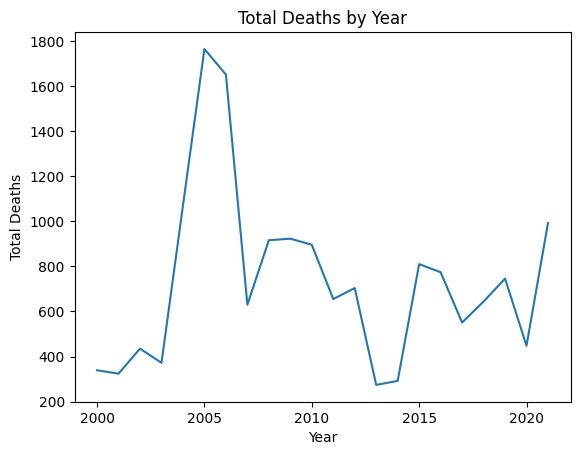

In [25]:
import matplotlib.pyplot as plt

df_group = df.groupby("Year")["Total Deaths"].sum()
spearman_year = stats.spearmanr(df_group.index, df_group.values)
print(f"statistik {i} : {spearman_year.statistic}")
print(f"p value {i}: {spearman_year.pvalue}")

plt.plot(df_group.index, df_group.values)
plt.xlabel("Year")
plt.ylabel("Total Deaths")
plt.title("Total Deaths by Year")
plt.show()